<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta9_g%C3%B6rev4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


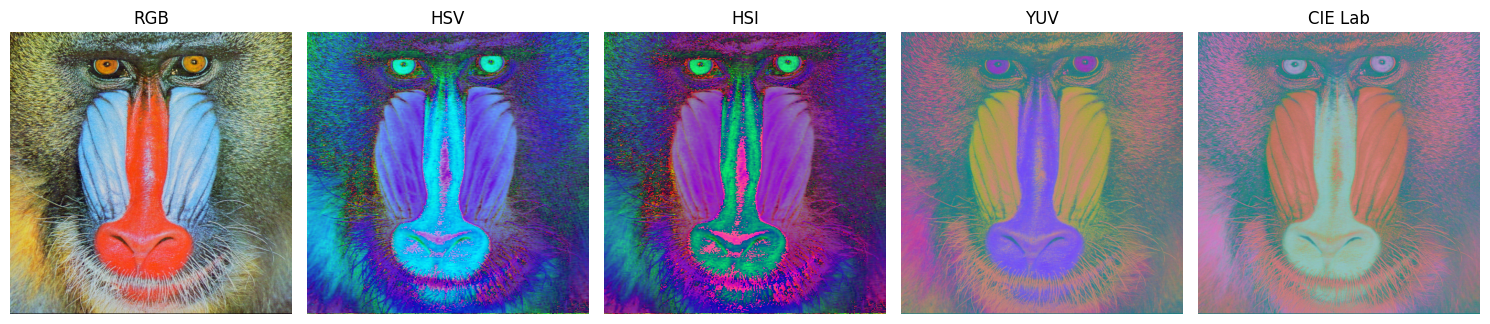

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

def bgr_to_hsi(bgr_img):
    rgb = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    r, g, b = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]

    intensity = (r + g + b) / 3.0

    min_rgb = np.minimum(np.minimum(r, g), b)
    sum_rgb = r + g + b
    saturation = np.where(sum_rgb > 1e-6, 1.0 - (3.0 * min_rgb / np.maximum(sum_rgb, 1e-6)), 0.0)
    saturation = np.clip(saturation, 0.0, 1.0)

    num = 0.5 * ((r - g) + (r - b))
    den = np.sqrt((r - g) ** 2 + (r - b) * (g - b)) + 1e-6
    theta = np.arccos(np.clip(num / den, -1.0, 1.0))

    hue = np.where(b <= g, theta, 2.0 * np.pi - theta)
    hue_norm = hue / (2.0 * np.pi)

    hsi_uint8 = np.stack([
        np.clip(hue_norm * 255.0, 0, 255),
        np.clip(saturation * 255.0, 0, 255),
        np.clip(intensity * 255.0, 0, 255)
    ], axis=-1).astype(np.uint8)
    return hsi_uint8

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/baboon.jpg'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
sample_bgr = cv2.imdecode(arr, cv2.IMREAD_COLOR)

rgb_bmp_path = "ornek_rgb.bmp"
cv2.imwrite(rgb_bmp_path, sample_bgr)

img_bgr = cv2.imread(rgb_bmp_path, cv2.IMREAD_COLOR)
assert img_bgr is not None, "BMP görüntüsü açılamadı!"

img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_hsi = bgr_to_hsi(img_bgr)
img_yuv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YUV)
img_lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

cv2.imwrite("cikti_hsv.bmp", img_hsv)
cv2.imwrite("cikti_hsi.bmp", img_hsi)
cv2.imwrite("cikti_yuv.bmp", img_yuv)
cv2.imwrite("cikti_lab.bmp", img_lab)

plt.figure(figsize=(15, 4))

plt.subplot(1, 5, 1)
plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
plt.title("RGB")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(img_hsv)
plt.title("HSV")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(img_hsi)
plt.title("HSI")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(img_yuv)
plt.title("YUV")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(img_lab)
plt.title("CIE Lab")
plt.axis("off")

plt.tight_layout()
plt.show()